# 04 · Explainability (SHAP) & AI Summaries

**Goal:** explain *why* the model flags a booking, and turn that into a plain-English note for hotel staff.

**Input:** saved model from notebook 03 + `data/hotel_bookings_clean.csv`

The Gemini key is read from `.env` as `Google_api_key`.

In [10]:
import os
import joblib
import numpy as np
import pandas as pd
import shap
from dotenv import load_dotenv
from google import genai
from sklearn.model_selection import train_test_split

model = joblib.load("../models/lgbm_model.pkl")
columns = joblib.load("../models/feature_columns.pkl")
threshold = joblib.load("../models/threshold.pkl")

## 1. Rebuild the test set

Same preparation and split as notebook 03 (same `random_state`), so we explain bookings the model never saw.

In [11]:
df = pd.read_csv("../data/hotel_bookings_clean.csv")

df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["has_kids"] = ((df["children"] + df["babies"]) > 0).astype(int)
df["has_agent"] = (df["agent"] != 0).astype(int)
df["ever_canceled_before"] = (df["previous_cancellations"] > 0).astype(int)

months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
df["arrival_month"] = df["arrival_date_month"].map({m: i + 1 for i, m in enumerate(months)})
top_countries = df["country"].value_counts().head(10).index
df["country"] = df["country"].where(df["country"].isin(top_countries), "Other")
df = df.drop(columns=["arrival_date_month", "arrival_date_year", "agent", "assigned_room_type"])

X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]
X = pd.get_dummies(X, columns=X.select_dtypes(include=["object", "string"]).columns, drop_first=True)
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_test = X_test[columns].astype(float)   # SHAP prefers numbers over True/False
test_prob = model.predict_proba(X_test)[:, 1]

## 2. Global importance: which features matter most?

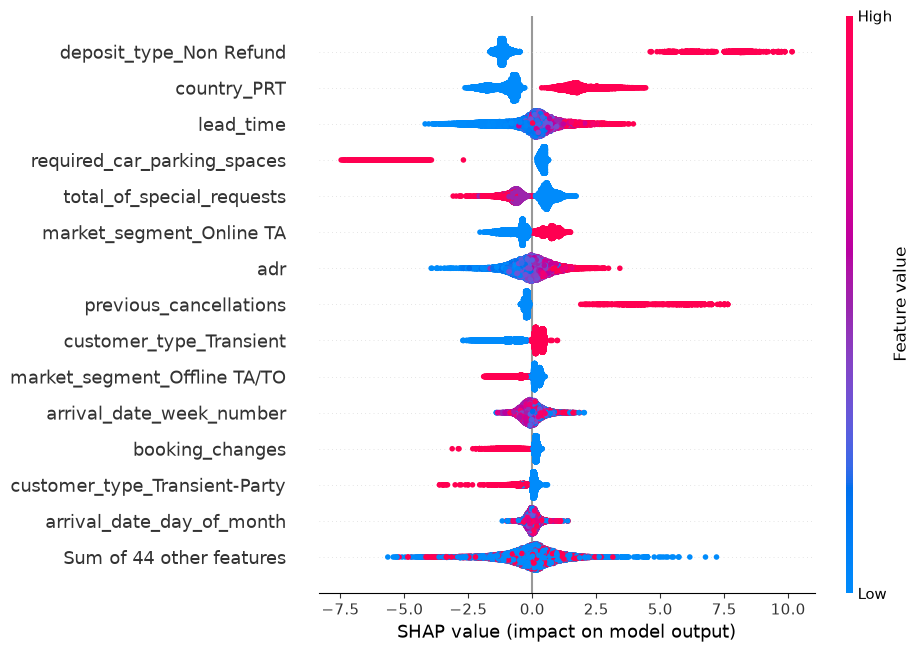

In [12]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.plots.beeswarm(shap_values, max_display=15)

In [13]:
importance = pd.DataFrame({
    "feature": X_test.columns,
    "mean_abs_shap": np.abs(shap_values.values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

importance.head(10).to_string(index=False)

'                     feature  mean_abs_shap\n     deposit_type_Non Refund       1.969481\n                 country_PRT       1.384876\n                   lead_time       0.806819\n required_car_parking_spaces       0.730162\n   total_of_special_requests       0.686375\n    market_segment_Online TA       0.644487\n                         adr       0.553217\n      previous_cancellations       0.469733\n     customer_type_Transient       0.411768\nmarket_segment_Offline TA/TO       0.332369'

## 3. Local explanation: why was *this* booking scored this way?

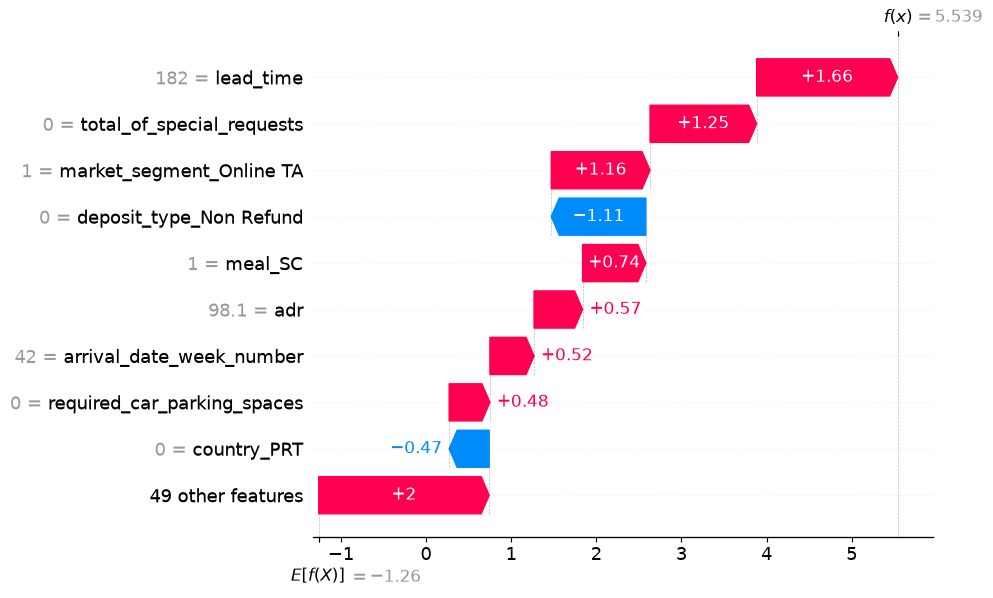

- lead_time = 182 (increases cancellation risk)
- total_of_special_requests = 0 (increases cancellation risk)
- market_segment_Online TA = 1 (increases cancellation risk)
- deposit_type_Non Refund = 0 (decreases cancellation risk)
- meal_SC = 1 (increases cancellation risk)


In [14]:
def get_reasons(i, top_n=5):
    """Return (probability, bullet list of the top SHAP factors) for test booking i."""
    contrib = pd.DataFrame({
        "feature": X_test.columns,
        "value": X_test.iloc[i].values,
        "shap": shap_values.values[i],
    })
    contrib = contrib.reindex(contrib["shap"].abs().sort_values(ascending=False).index)
    lines = [
        f"- {r.feature} = {r.value:g} ({'increases' if r.shap > 0 else 'decreases'} cancellation risk)"
        for r in contrib.head(top_n).itertuples()
    ]
    return test_prob[i], "\n".join(lines)


risky = np.where(test_prob > 0.9)[0][0]
shap.plots.waterfall(shap_values[risky], max_display=10)
print(get_reasons(risky)[1])

## 4. Plain-English summary with Gemini

Turns the SHAP factors into a short note for front-desk staff. Requires `Google_api_key` in `.env`.

In [ ]:
load_dotenv()
client = genai.Client(api_key=os.getenv("Google_api_key"))


def generate_summary(i):
    prob, reasons = get_reasons(i)
    prompt = f"""You are an assistant for hotel front-desk staff.
A machine learning model predicted this booking's cancellation probability as {prob:.0%}.
The main factors behind this prediction are:
{reasons}

Feature notes: lead_time = days between booking and arrival.
One-hot columns like market_segment_Online TA = 1 mean the booking belongs to that category; 0 means it does not.

Write a short note for hotel staff (3-4 sentences, plain English, no technical terms):
1. State the risk level (Low / Medium / High).
2. Explain the main reasons simply.
3. Suggest one or two practical actions the hotel can take."""
    return client.models.generate_content(model="gemini-3.1-flash-lite", contents=prompt).text


print(generate_summary(risky))

**Cancellation Risk: High**

This booking has a very high probability of being cancelled. The main reasons are that it was booked very far in advance through an online travel agency, the guest made no special requests, and the specific meal plan chosen. Given this high likelihood, consider holding off on allocating specific resources for this room or be ready to re-market it closer to the arrival date.
